<hr>
<h1>
<h2 align="center">Data Engineering Project Challenge</h2>
<h3 align="center">Aline Nyiranizeyimana</h3>

<h2 align="center">Last Mile Logistics Audit</h2>
<h4 align="center"><em>Veridi Logistics</em></h4>

<hr>

Data: Olist Brazilian e-commerce dataset (Kaggle).

The CEO's question: **are we failing specific regions, or is this a nationwide problem?** She also thinks the estimated delivery dates we give customers are inaccurate.

What I do in this notebook:
1. Join orders, reviews and customers into one table
2. Work out how late each order was and label it On Time / Late / Super Late
3. Look at late % by state (map + charts)
4. Check if late deliveries really cause bad reviews
5. Bonus: product categories in English
6. My extra analysis: how much lateness comes from sellers handing parcels over late, and how much happens after hand-off?

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
from matplotlib.patches import Patch
from matplotlib.collections import PolyCollection

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 150)
pd.options.display.float_format = '{:,.2f}'.format

## 1. Load the data

In [2]:
orders = pd.read_csv('olist_orders_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')
geo = pd.read_csv('olist_geolocation_dataset.csv')
translation = pd.read_csv('product_category_name_translation.csv')

for name, table in [('orders', orders), ('reviews', reviews), ('customers', customers), ('products', products),
                    ('items', items), ('sellers', sellers), ('geolocation', geo), ('translation', translation)]:
    print(name, table.shape)

orders (99441, 8)
reviews (99224, 7)
customers (99441, 5)
products (32951, 9)
items (112650, 7)
sellers (3095, 4)
geolocation (1000163, 5)
translation (71, 2)


 change date columns into real dates

In [3]:
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])
items['shipping_limit_date'] = pd.to_datetime(items['shipping_limit_date'])

orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


## 2. Story 1 - The Schema Builder (master table)

Orders is the main table, one row per order. The danger is that some orders have more than one review, so a plain join would copy those orders and I'd end up with more rows than orders. Let me check that first.

In [4]:
print('rows in orders:', len(orders))
print('unique order ids in orders:', orders['order_id'].nunique())
print()
print('rows in reviews:', len(reviews))
print('unique order ids in reviews:', reviews['order_id'].nunique())

orders_reviews_plain_left_join = orders.merge(reviews, on='order_id', how='left')
print()
print('rows after a plain join:', len(orders_reviews_plain_left_join), '(should be', len(orders), ')')

rows in orders: 99441
unique order ids in orders: 99441

rows in reviews: 99224
unique order ids in reviews: 98673

rows after a plain join: 99992 (should be 99441 )


Ensuring no 1-to-many joins error

In [5]:
reviews = reviews.sort_values('review_answer_timestamp')
reviews_clean = reviews.drop_duplicates(subset='order_id', keep='last')
print('reviews after removing duplicates:', len(reviews_clean))

df = orders.merge(reviews_clean[['order_id', 'review_score']], on='order_id', how='left')
df = df.merge(customers[['customer_id', 'customer_state', 'customer_city']], on='customer_id', how='left')

print('rows in master table:', len(df))
print('same as orders?', len(df) == len(orders))
print('order ids unique?', df['order_id'].is_unique)
print('orders with no review:', df['review_score'].isna().sum())

reviews after removing duplicates: 98673
rows in master table: 99441
same as orders? True
order ids unique? True
orders with no review: 768


Same number of rows as the orders table, so no duplicates. The fix I used was to keep one review per order (the latest) and use left joins.

In [6]:
region_states = {
    'North': ['AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO'],
    'Northeast': ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'],
    'Central-West': ['DF', 'GO', 'MT', 'MS'],
    'Southeast': ['ES', 'MG', 'RJ', 'SP'],
    'South': ['PR', 'RS', 'SC'],
}
state_to_region = {}
for region, states in region_states.items():
    for s in states:
        state_to_region[s] = region

df['region'] = df['customer_state'].map(state_to_region)
df[['order_id', 'order_status', 'review_score', 'customer_state', 'region']].head()

,order_id,order_status,review_score,customer_state,region
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,4.00,SP,Southeast
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,4.00,BA,Northeast
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,5.00,GO,Central-West
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,5.00,RN,Northeast
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,5.00,SP,Southeast


## 3. Story 2 - The real delay calculator

`Days_Difference = estimated delivery date - actual delivery date`

- positive = arrived early
- negative = arrived late

Labels: **On Time** (0 or more), **Late** (1 to 5 days late), **Super Late** (more than 5 days late).

Orders that were never delivered (canceled, unavailable, still shipping) have no delivery date, so I leave them out of the delay analysis.

In [7]:
print(df['order_status'].value_counts())
print()
print('orders with no delivery date:', df['order_delivered_customer_date'].isna().sum())

delivered = df[(df['order_status'] == 'delivered') & (df['order_delivered_customer_date'].notna())].copy()

print()
print('orders kept:', len(delivered))
print('orders left out:', len(df) - len(delivered))
print()
print('status of the orders that were left out:')
left_out = df[~df['order_id'].isin(delivered['order_id'])]
print(left_out['order_status'].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

orders with no delivery date: 2965

orders kept: 96470
orders left out: 2971

status of the orders that were left out:
order_status
shipped        1107
canceled        625
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [8]:
estimated = delivered['order_estimated_delivery_date'].dt.normalize()
actual = delivered['order_delivered_customer_date'].dt.normalize()
bought = delivered['order_purchase_timestamp'].dt.normalize()

delivered['Days_Difference'] = (estimated - actual).dt.days
delivered['promised_days'] = (estimated - bought).dt.days
delivered['actual_days'] = (actual - bought).dt.days

def get_status(days):
    if days >= 0:
        return 'On Time'
    elif days >= -5:
        return 'Late'
    else:
        return 'Super Late'

delivered['delivery_status'] = delivered['Days_Difference'].apply(get_status)
delivered['is_late'] = delivered['delivery_status'] != 'On Time'

status_order = ['On Time', 'Late', 'Super Late']
status_colors = {'On Time': '#2a9d8f', 'Late': '#f4a261', 'Super Late': '#d62828'}

counts = delivered['delivery_status'].value_counts().reindex(status_order)
print(counts)
print()
print((counts / len(delivered) * 100).round(1))

delivery_status
On Time       89936
Late           2770
Super Late     3764
Name: count, dtype: int64

delivery_status
On Time      93.20
Late          2.90
Super Late    3.90
Name: count, dtype: float64


Distribution of Days_Difference (I cut it at -30 and 40 so the chart is readable)

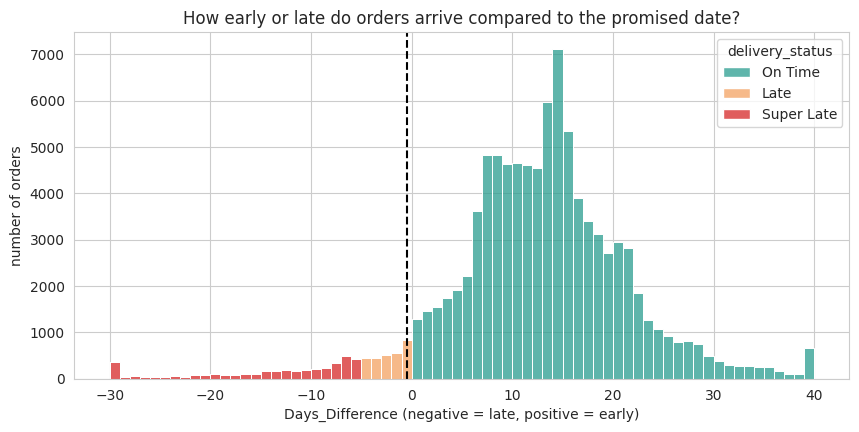

In [9]:
plot_data = delivered[['Days_Difference', 'delivery_status']].copy()
plot_data['Days_Difference'] = plot_data['Days_Difference'].clip(-30, 40)

plt.figure(figsize=(10, 4.5))
sns.histplot(data=plot_data, x='Days_Difference', hue='delivery_status', hue_order=status_order,
             palette=status_colors, multiple='stack', binwidth=1)
plt.axvline(-0.5, color='black', linestyle='--')
plt.title('How early or late do orders arrive compared to the promised date?')
plt.xlabel('Days_Difference (negative = late, positive = early)')
plt.ylabel('number of orders')
plt.show()

In [10]:
late_pct = delivered['is_late'].mean() * 100
super_late_pct = (delivered['delivery_status'] == 'Super Late').mean() * 100
early_pct = (delivered['Days_Difference'] > 0).mean() * 100

print('late orders:', round(late_pct, 1), '%')
print('super late orders:', round(super_late_pct, 1), '%')
print('median Days_Difference:', delivered['Days_Difference'].median(), '(positive = early)')
print('orders that arrived before the estimate:', round(early_pct, 1), '%')
print()
print('average promised days:', round(delivered['promised_days'].mean(), 1))
print('average actual days:', round(delivered['actual_days'].mean(), 1))

late orders: 6.8 %
super late orders: 3.9 %
median Days_Difference: 12.0 (positive = early)
orders that arrived before the estimate: 91.9 %

average promised days: 24.4
average actual days: 12.5


So the CEO's idea that we over-promise is not really true on average. Most orders (about 92%) arrive before the estimated date and the median order comes 12 days early. The estimates are padded, not too optimistic. The issue is the 6.8% that arrive late. Below I check if the padding is the same everywhere (it isn't).

## 4. Story 3 - Which states are late?

In [11]:
delivered['is_super_late'] = delivered['delivery_status'] == 'Super Late'

state = delivered.groupby('customer_state').agg(
    orders=('order_id', 'count'),
    late_orders=('is_late', 'sum'),
    late_pct=('is_late', 'mean'),
    super_late_pct=('is_super_late', 'mean'),
    avg_promised=('promised_days', 'mean'),
    avg_actual=('actual_days', 'mean'),
    avg_review=('review_score', 'mean'),
)
state['late_pct'] = state['late_pct'] * 100
state['super_late_pct'] = state['super_late_pct'] * 100
state['region'] = state.index.map(state_to_region)

national_late = delivered['is_late'].mean() * 100
print('national late rate:', round(national_late, 1), '%')
print()
print('worst 8 states:')
print(state.sort_values('late_pct', ascending=False).head(8))
print()
print('best 5 states:')
print(state.sort_values('late_pct').head(5))

national late rate: 6.8 %

worst 8 states:
                orders  late_orders  late_pct  super_late_pct  avg_promised  avg_actual  avg_review     region
customer_state                                                                                                
AL                 397           85     21.41           12.85         33.21       24.50        3.85  Northeast
MA                 717          125     17.43           10.32         31.08       21.51        3.83  Northeast
SE                 335           51     15.22           11.64         31.48       21.46        3.91  Northeast
PI                 476           66     13.87            7.35         30.70       19.39        3.99  Northeast
CE                1279          176     13.76           10.24         32.00       21.20        3.94  Northeast
RR                  41            5     12.20            9.76         46.63       29.34        3.90      North
BA                3256          396     12.16            7.59        

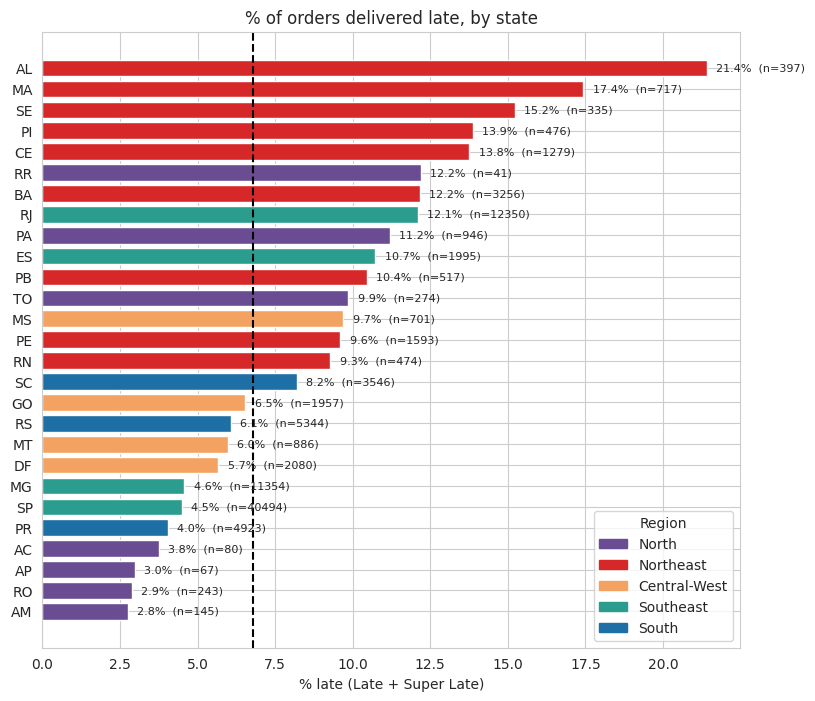

In [12]:
region_colors = {'North': '#6a4c93', 'Northeast': '#d62828', 'Central-West': '#f4a261',
                 'Southeast': '#2a9d8f', 'South': '#1d6fa5'}

state_sorted = state.sort_values('late_pct')

plt.figure(figsize=(9, 8))
plt.barh(state_sorted.index, state_sorted['late_pct'], color=state_sorted['region'].map(region_colors))
plt.axvline(national_late, color='black', linestyle='--')

for i, (pct, n) in enumerate(zip(state_sorted['late_pct'], state_sorted['orders'])):
    plt.text(pct + 0.3, i, str(round(pct, 1)) + '%  (n=' + str(n) + ')', va='center', fontsize=8)

handles = [Patch(color=c, label=r) for r, c in region_colors.items()]
plt.legend(handles=handles, loc='lower right', title='Region')
plt.title('% of orders delivered late, by state')
plt.xlabel('% late (Late + Super Late)')
plt.show()

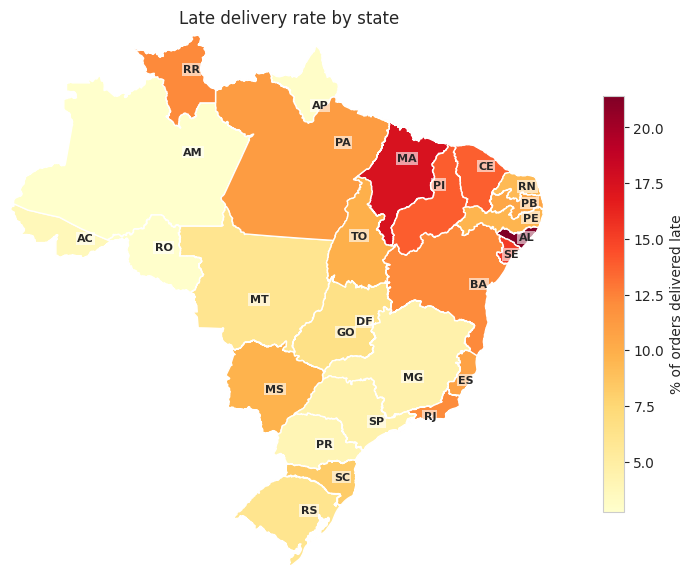

In [13]:
geo = geo[(geo['geolocation_lat'].between(-34, 6)) & (geo['geolocation_lng'].between(-74, -34))]
centers = geo.groupby('geolocation_state')[['geolocation_lat', 'geolocation_lng']].mean()
state['lat'] = centers['geolocation_lat']
state['lng'] = centers['geolocation_lng']

url = 'https://raw.githubusercontent.com/codeforamerica/click_that_hood/main/public/data/brazil-states.geojson'
try:
    brazil = json.load(urllib.request.urlopen(url, timeout=30))
except Exception as e:
    brazil = None
    print('could not download the map borders:', e)

if brazil is not None:
    cmap = plt.get_cmap('YlOrRd')
    low, high = state['late_pct'].min(), state['late_pct'].max()

    shapes = []
    colors = []
    for feature in brazil['features']:
        code = feature['properties']['sigla']
        geometry = feature['geometry']
        if geometry['type'] == 'MultiPolygon':
            polygons = geometry['coordinates']
        else:
            polygons = [geometry['coordinates']]
        for polygon in polygons:
            shapes.append(np.array(polygon[0]))
            colors.append(cmap((state.loc[code, 'late_pct'] - low) / (high - low)))

    fig, ax = plt.subplots(figsize=(9, 9))
    ax.add_collection(PolyCollection(shapes, facecolors=colors, edgecolors='white'))
    for code, row in state.iterrows():
        ax.text(row['lng'], row['lat'], code, ha='center', va='center', fontsize=8, fontweight='bold',
                bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=1))
    ax.set_xlim(-74, -33)
    ax.set_ylim(-34.5, 5.5)
    ax.set_aspect('equal')
    ax.axis('off')
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(low, high))
    fig.colorbar(sm, ax=ax, shrink=0.6, label='% of orders delivered late')
    ax.set_title('Late delivery rate by state')
    plt.show()

### Are remote states hit harder?

Most sellers are in Sao Paulo, so I treat Sao Paulo as the distribution center and measure the distance from each state to it.

share of sellers in SP: 59.7 %


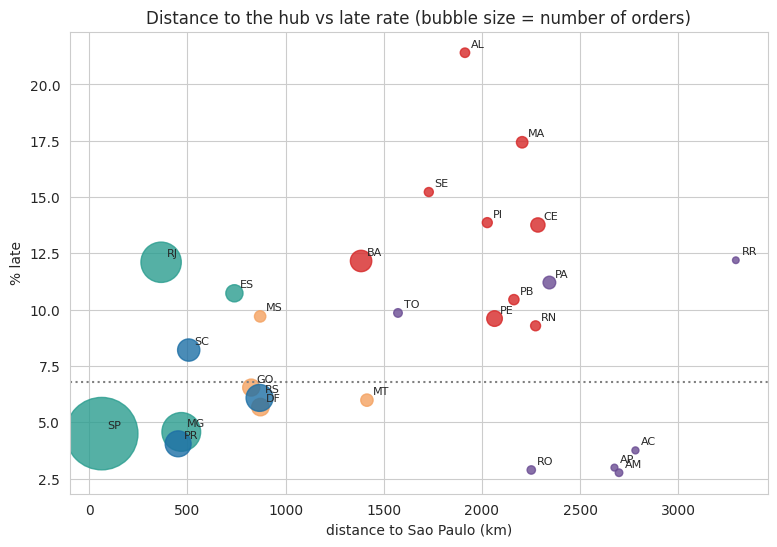

correlation between distance and late % (27 states): 0.07

                distance_km  late_pct
customer_state                       
AM                 2,698.03      2.76
AP                 2,674.83      2.99
AC                 2,781.67      3.75
RO                 2,251.26      2.88
CE                 2,285.03     13.76
RN                 2,273.19      9.28
MA                 2,204.81     17.43
PA                 2,343.51     11.21


In [14]:
print('share of sellers in SP:', round((sellers['seller_state'] == 'SP').mean() * 100, 1), '%')

def distance_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = np.radians(lat1), np.radians(lng1), np.radians(lat2), np.radians(lng2)
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

state['distance_km'] = distance_km(state['lat'], state['lng'], -23.55, -46.63)

plt.figure(figsize=(9, 6))
plt.scatter(state['distance_km'], state['late_pct'], s=state['orders'] / 15 + 20,
            c=state['region'].map(region_colors), alpha=0.8)
for code, row in state.iterrows():
    plt.annotate(code, (row['distance_km'], row['late_pct']), xytext=(4, 4), textcoords='offset points', fontsize=8)
plt.axhline(national_late, color='grey', linestyle=':')
plt.xlabel('distance to Sao Paulo (km)')
plt.ylabel('% late')
plt.title('Distance to the hub vs late rate (bubble size = number of orders)')
plt.show()

corr = state['distance_km'].corr(state['late_pct'], method='spearman')
print('correlation between distance and late % (27 states):', round(corr, 2))
print()
print(state.loc[['AM', 'AP', 'AC', 'RO', 'CE', 'RN', 'MA', 'PA'], ['distance_km', 'late_pct']])

In [15]:
state['remote'] = state['distance_km'] > 1500
delivered['remote'] = delivered['customer_state'].map(state['remote'])
print(delivered.groupby('remote')['is_late'].mean() * 100)
print()
print('remote states:', list(state[state['remote']].index))
print()

region_table = delivered.groupby('region').agg(
    orders=('order_id', 'count'),
    late_pct=('is_late', 'mean'),
    super_late_pct=('is_super_late', 'mean'),
    avg_review=('review_score', 'mean'))
region_table[['late_pct', 'super_late_pct']] = region_table[['late_pct', 'super_late_pct']] * 100
print(region_table.sort_values('late_pct', ascending=False))

remote
False    6.33
True    11.97
Name: is_late, dtype: float64

remote states: ['AC', 'AL', 'AM', 'AP', 'CE', 'MA', 'PA', 'PB', 'PE', 'PI', 'RN', 'RO', 'RR', 'SE', 'TO']

              orders  late_pct  super_late_pct  avg_review
region                                                    
Northeast       9044     12.72            8.24        3.97
North           1796      8.57            5.85        4.03
Central-West    5624      6.53            3.49        4.13
Southeast      66193      6.12            3.41        4.18
South          13813      5.90            3.32        4.19


Distance on its own does not explain it. The northeast states are bad, but AM, AP and AC are further from Sao Paulo than any northeast state, and RO is about as far as CE and RN (see the table above). Those four states have the lowest late rates. Let me look at what we promised them compared to what really happened.

In [16]:
state['cushion'] = state['avg_promised'] - state['avg_actual']

print(state.sort_values('late_pct', ascending=False)[['avg_promised', 'avg_actual', 'cushion', 'late_pct']].head(6))
print()
print(state.sort_values('late_pct')[['avg_promised', 'avg_actual', 'cushion', 'late_pct']].head(5))
print()
print('cushion range:', round(state['cushion'].min(), 1), 'to', round(state['cushion'].max(), 1), 'days')
print('correlation between cushion and late %:', round(state['cushion'].corr(state['late_pct'], method='spearman'), 2))

state['median_promised'] = delivered.groupby('customer_state')['promised_days'].median()
state['p90_actual'] = delivered.groupby('customer_state')['actual_days'].quantile(0.9)
state['promise_minus_p90'] = state['median_promised'] - state['p90_actual']
print()
print(state.sort_values('late_pct', ascending=False)[['median_promised', 'p90_actual', 'promise_minus_p90', 'late_pct']].head(6))

                avg_promised  avg_actual  cushion  late_pct
customer_state                                             
AL                     33.21       24.50     8.71     21.41
MA                     31.08       21.51     9.57     17.43
SE                     31.48       21.46    10.02     15.22
PI                     30.70       19.39    11.31     13.87
CE                     32.00       21.20    10.80     13.76
RR                     46.63       29.34    17.29     12.20

                avg_promised  avg_actual  cushion  late_pct
customer_state                                             
AM                     45.92       26.36    19.57      2.76
RO                     39.39       19.28    20.10      2.88
AP                     46.87       27.18    19.69      2.99
AC                     41.73       21.00    20.73      3.75
PR                     25.25       11.94    13.31      4.04

cushion range: 8.7 to 20.7 days
correlation between cushion and late %: -0.7

                medi

The Amazon states (AM, AP, AC, RO) have a cushion of about 20 days (they are promised 39 to 47 days), against 9 to 10 days in AL, MA and SE. So the estimate is not too short everywhere, but it is not adjusted to how unpredictable deliveries are in each state.

The correlation between cushion and late % (-0.7) is partly built in, because late % is by definition the share of orders that go past the promise, so I would not use it as proof. A better example is AL: the typical promise is 32 days, but the slowest 10% of orders take about 39 days or more, so more than 10% of AL orders cannot meet the promise (promise minus slowest-10% time = -7.4 days). MA, SE and CE are also negative.

### Is it the same problem every month?

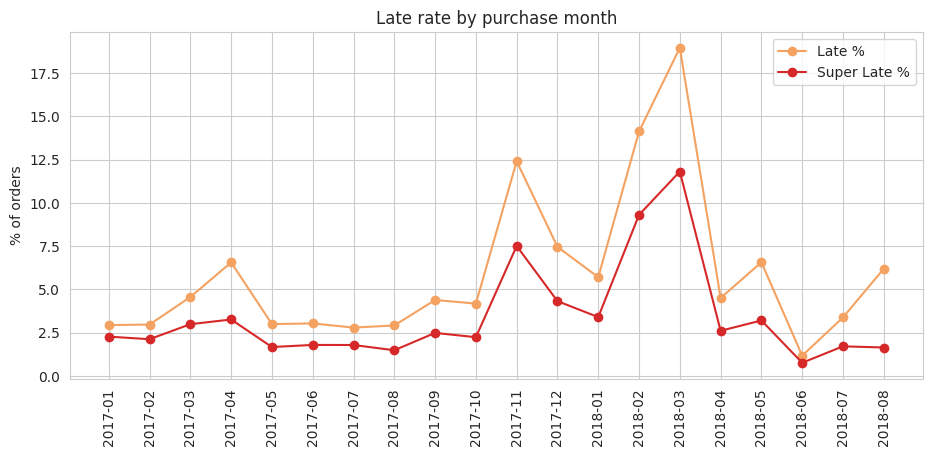

         orders  late_pct  super_late_pct  avg_review
month                                                
2018-03    7003     18.96           11.81        3.81
2018-02    6555     14.13            9.31        3.88
2017-11    7288     12.40            7.51        3.99
2017-12    5513      7.46            4.32        4.09


In [17]:
delivered['month'] = delivered['order_purchase_timestamp'].dt.to_period('M').astype(str)

monthly = delivered.groupby('month').agg(orders=('order_id', 'count'), late_pct=('is_late', 'mean'),
                                         super_late_pct=('is_super_late', 'mean'), avg_review=('review_score', 'mean'))
monthly['late_pct'] = monthly['late_pct'] * 100
monthly['super_late_pct'] = monthly['super_late_pct'] * 100
monthly = monthly[monthly['orders'] >= 300]

plt.figure(figsize=(11, 4.5))
plt.plot(monthly.index, monthly['late_pct'], marker='o', color='#f4a261', label='Late %')
plt.plot(monthly.index, monthly['super_late_pct'], marker='o', color='#d62828', label='Super Late %')
plt.xticks(rotation=90)
plt.ylabel('% of orders')
plt.title('Late rate by purchase month')
plt.legend()
plt.show()

print(monthly.sort_values('late_pct', ascending=False).head(4))

In [18]:
spike_months = monthly.sort_values('late_pct').tail(3).index
print('worst months:', list(spike_months))

delivered['spike'] = delivered['month'].isin(spike_months)

share_orders = delivered['spike'].mean() * 100
share_late = delivered[delivered['is_late']]['spike'].mean() * 100
print('these months have', round(share_orders), '% of the orders but', round(share_late), '% of the late orders')
print()
print('late % in normal months:', round(delivered[~delivered['spike']]['is_late'].mean() * 100, 1))
print('late % in the 3 worst months:', round(delivered[delivered['spike']]['is_late'].mean() * 100, 1))
print()

by_region = delivered.pivot_table(index='region', columns='spike', values='is_late', aggfunc='mean') * 100
by_region.columns = ['normal months', 'worst 3 months']
print(by_region.sort_values('normal months', ascending=False))

worst months: ['2017-11', '2018-02', '2018-03']
these months have 22 % of the orders but 48 % of the late orders

late % in normal months: 4.5
late % in the 3 worst months: 15.1

              normal months  worst 3 months
region                                     
Northeast              9.33           25.34
North                  5.33           22.00
Southeast              4.04           13.65
Central-West           3.70           16.21
South                  3.47           14.52


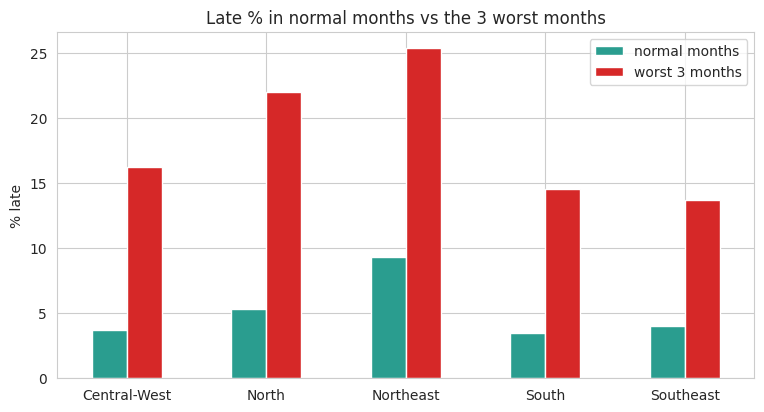

                orders  late_orders  late_pct  share_of_late_orders
customer_state                                                     
SP               40494         1820      4.49                 27.85
RJ               12350         1495     12.11                 22.88
MG               11354          519      4.57                  7.94
BA                3256          396     12.16                  6.06
RS                5344          325      6.08                  4.97

late orders in Rio de Janeiro: 1495
late orders in the whole Northeast: 1150
Rio late % in normal months: 6.6 | in the 3 worst months: 31.2
share of Rio late orders that fall in the 3 worst months: 58 %


In [19]:
by_region.plot(kind='bar', figsize=(9, 4.5), color=['#2a9d8f', '#d62828'])
plt.ylabel('% late')
plt.xlabel('')
plt.xticks(rotation=0)
plt.title('Late % in normal months vs the 3 worst months')
plt.show()

state['share_of_late_orders'] = state['late_orders'] / state['late_orders'].sum() * 100
print(state.sort_values('late_orders', ascending=False)[['orders', 'late_orders', 'late_pct', 'share_of_late_orders']].head(5))
print()
print('late orders in Rio de Janeiro:', int(state.loc['RJ', 'late_orders']))
print('late orders in the whole Northeast:', int(state[state['region'] == 'Northeast']['late_orders'].sum()))

rj = delivered[delivered['customer_state'] == 'RJ']
print('Rio late % in normal months:', round(rj[~rj['spike']]['is_late'].mean() * 100, 1),
      '| in the 3 worst months:', round(rj[rj['spike']]['is_late'].mean() * 100, 1))
print('share of Rio late orders that fall in the 3 worst months:', round(rj[rj['is_late']]['spike'].mean() * 100), '%')

**What I found for the CEO's question**

- It is both. The late rate was 15.1% in the 3 worst months (Nov 2017, Feb 2018, Mar 2018) against 4.5% in all the other months, and it went up in every region. I chose these months because they were the worst, so the share of late orders in them (48%) is partly built in. The gap in the late rate is the better evidence. I don't know what happened in those months, the data doesn't say (Nov 2017 is Black Friday, but Feb and Mar are not an obvious retail peak).
- On top of that the Northeast is worse than the rest of the country even in normal months (about 9% late compared to 3.5-5% in the other regions).
- Rio de Janeiro is close to Sao Paulo but has more late orders than the whole Northeast. About 58% of its late orders (860 of 1,495) are in those 3 months, so it is mostly about those months.

## 5. Story 4 - Do late deliveries cause bad reviews?

In [20]:
rev = delivered.dropna(subset=['review_score']).copy()
print('orders with a delivery date and a review:', len(rev))

avg_review = rev.groupby('delivery_status')['review_score'].agg(['mean', 'count']).reindex(status_order)
avg_review['one_star_pct'] = (rev['review_score'] == 1).groupby(rev['delivery_status']).mean().reindex(status_order) * 100
print(avg_review)
print()
print('average score on time:', round(rev[~rev['is_late']]['review_score'].mean(), 2))
print('average score late (late + super late):', round(rev[rev['is_late']]['review_score'].mean(), 2))

orders with a delivery date and a review: 95824
                 mean  count  one_star_pct
delivery_status                           
On Time          4.29  89443          6.62
Late             2.99   2722         33.61
Super Late       1.74   3659         68.76

average score on time: 4.29
average score late (late + super late): 2.27


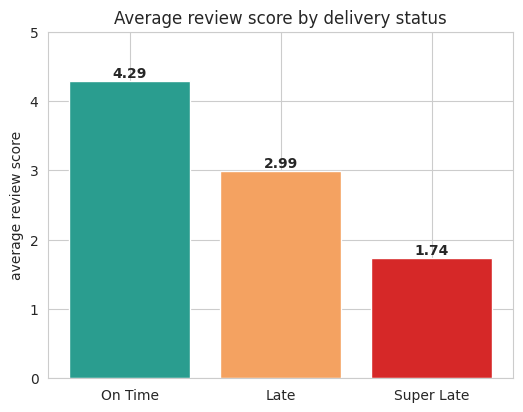

In [21]:
plt.figure(figsize=(6, 4.5))
plt.bar(status_order, avg_review['mean'], color=[status_colors[s] for s in status_order])
for i, value in enumerate(avg_review['mean']):
    plt.text(i, value + 0.05, str(round(value, 2)), ha='center', fontweight='bold')
plt.ylim(0, 5)
plt.ylabel('average review score')
plt.title('Average review score by delivery status')
plt.show()

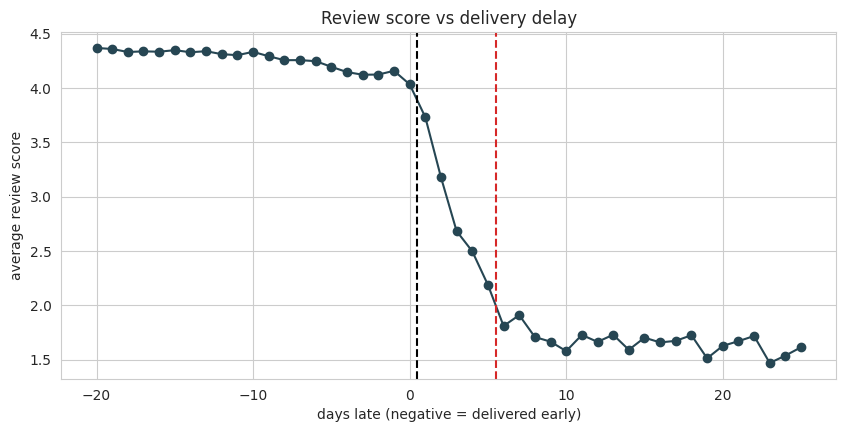

days_late
-20   4.37
-7    4.26
 0    4.03
 1    3.73
 2    3.18
 3    2.68
 6    1.81
 10   1.58
Name: mean, dtype: float64

spearman correlation (Days_Difference vs score): 0.18


In [22]:
rev['days_late'] = -rev['Days_Difference']
per_day = rev[rev['days_late'].between(-20, 25)].groupby('days_late')['review_score'].agg(['mean', 'count'])
per_day = per_day[per_day['count'] >= 30]

plt.figure(figsize=(10, 4.5))
plt.plot(per_day.index, per_day['mean'], marker='o', color='#264653')
plt.axvline(0.5, color='black', linestyle='--')
plt.axvline(5.5, color='#d62828', linestyle='--')
plt.xlabel('days late (negative = delivered early)')
plt.ylabel('average review score')
plt.title('Review score vs delivery delay')
plt.show()

print(per_day.loc[[-20, -7, 0, 1, 2, 3, 6, 10], 'mean'])
print()
print('spearman correlation (Days_Difference vs score):', round(rev['Days_Difference'].corr(rev['review_score'], method='spearman'), 2))

In [23]:
by_state = rev.groupby(['customer_state', 'is_late'])['review_score'].agg(['mean', 'count']).unstack()

enough = by_state[(by_state['count'][True] >= 30) & (by_state['count'][False] >= 30)]
gap = enough['mean'][False] - enough['mean'][True]
print('states with at least 30 late and 30 on time reviews:', len(enough), 'of', len(by_state))
print('states where late orders get a lower score:', (gap > 0).sum(), 'of', len(enough))
print(gap.describe())

states with at least 30 late and 30 on time reviews: 21 of 27
states where late orders get a lower score: 21 of 21
count   21.00
mean     2.05
std      0.24
min      1.63
25%      1.90
50%      2.03
75%      2.23
max      2.62
dtype: float64


Yes, late delivery clearly hurts reviews. The average score goes from 4.3 (on time) to 3.0 (late) to 1.7 (super late), and more than two thirds of super late orders get 1 star. The score stays around 4.2-4.4 when the parcel is early, then drops quickly right after the promised date. So being on time matters more than being fast. The same drop shows up in all 21 states that have enough reviews to compare (30 or more late and 30 or more on time reviews). The other 6 states have too few late reviews to check, so it is not just a regional thing.

This is observational data so it doesn't prove cause 100%, but it is very consistent.

## 6. Bonus - product categories in English

In [24]:
products = products.merge(translation, on='product_category_name', how='left')

missing = products[products['product_category_name'].notna() & products['product_category_name_english'].isna()]
print('categories without a translation:', list(missing['product_category_name'].unique()))

products.loc[products['product_category_name'] == 'pc_gamer', 'product_category_name_english'] = 'pc_gamer'
products.loc[products['product_category_name'] == 'portateis_cozinha_e_preparadores_de_alimentos',
             'product_category_name_english'] = 'portable_kitchen_food_preparers'

products['category'] = products['product_category_name_english'].fillna('unknown')
print('products without category:', (products['category'] == 'unknown').sum())
products[['product_category_name', 'category']].drop_duplicates().head()

categories without a translation: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
products without category: 610


,product_category_name,category
0,perfumaria,perfumery
1,artes,art
2,esporte_lazer,sports_leisure
3,bebes,baby
4,utilidades_domesticas,housewares


74 categories, 32 with 300+ orders


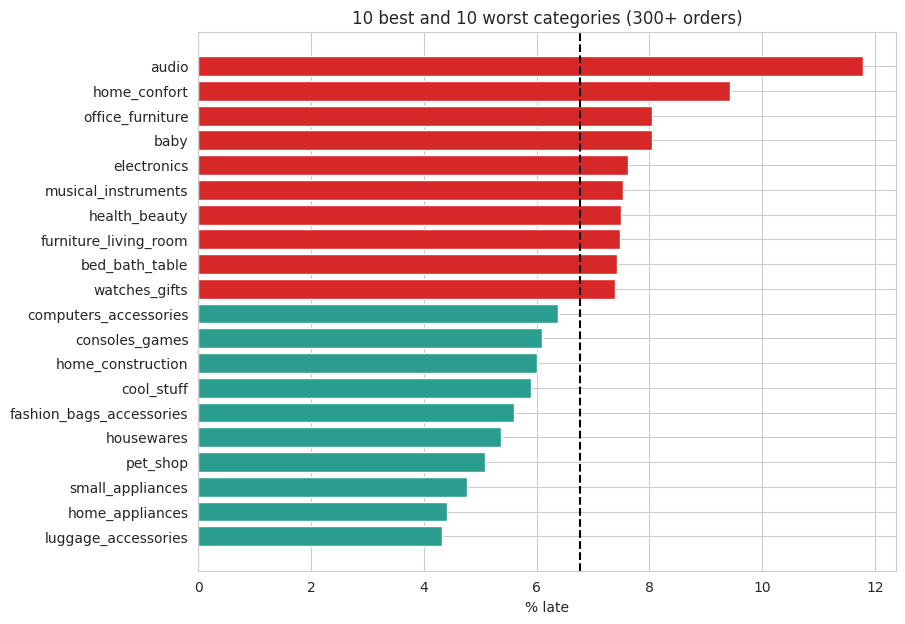

                  orders  late_pct  avg_review
category                                      
audio                348     11.78        3.84
home_confort         392      9.44        3.88
office_furniture    1254      8.05        3.64
baby                2809      8.05        4.10
electronics         2517      7.63        4.12


In [25]:
order_cat = items.merge(products[['product_id', 'category', 'product_weight_g']], on='product_id', how='left')
order_cat = order_cat[['order_id', 'category']].drop_duplicates()
order_cat = order_cat.merge(delivered[['order_id', 'customer_state', 'is_late', 'review_score']], on='order_id', how='inner')

category = order_cat.groupby('category').agg(orders=('order_id', 'count'), late_pct=('is_late', 'mean'),
                                             avg_review=('review_score', 'mean'))
category['late_pct'] = category['late_pct'] * 100

big = category[category['orders'] >= 300].sort_values('late_pct')
print(len(category), 'categories,', len(big), 'with 300+ orders')

top_and_bottom = pd.concat([big.head(10), big.tail(10)])
colors = ['#2a9d8f'] * 10 + ['#d62828'] * 10
plt.figure(figsize=(9, 7))
plt.barh(top_and_bottom.index, top_and_bottom['late_pct'], color=colors)
plt.axvline(national_late, color='black', linestyle='--')
plt.xlabel('% late')
plt.title('10 best and 10 worst categories (300+ orders)')
plt.show()

print(big.sort_values('late_pct', ascending=False).head(5))

In [26]:
furniture_names = [c for c in category.index if 'furniture' in c]
electronics_names = ['electronics', 'computers', 'computers_accessories', 'telephony', 'fixed_telephony', 'audio']
print('furniture:', furniture_names)
print('electronics:', electronics_names)

furniture = order_cat[order_cat['category'].isin(furniture_names)].drop_duplicates('order_id')
electronics = order_cat[order_cat['category'].isin(electronics_names)].drop_duplicates('order_id')

print()
print('furniture   - orders:', len(furniture), ' late %:', round(furniture['is_late'].mean() * 100, 1), ' avg review:', round(furniture['review_score'].mean(), 2))
print('electronics - orders:', len(electronics), ' late %:', round(electronics['is_late'].mean() * 100, 1), ' avg review:', round(electronics['review_score'].mean(), 2))

only_electronics = order_cat[order_cat['category'] == 'electronics']
print()
print("only the 'electronics' category - orders:", len(only_electronics), ' late %:', round(only_electronics['is_late'].mean() * 100, 1))

furniture: ['furniture_bedroom', 'furniture_decor', 'furniture_living_room', 'furniture_mattress_and_upholstery', 'kitchen_dining_laundry_garden_furniture', 'office_furniture']
electronics: ['electronics', 'computers', 'computers_accessories', 'telephony', 'fixed_telephony', 'audio']

furniture   - orders: 8327  late %: 7.2  avg review: 4.0
electronics - orders: 13862  late %: 6.9  avg review: 4.08

only the 'electronics' category - orders: 2517  late %: 7.6


Furniture is not harder to deliver on time than electronics (about 7.2% vs 6.9% late). "Electronics" here means 6 categories put together (electronics, computers, computers_accessories, telephony, fixed_telephony, audio). With only the `electronics` category it is 7.6% late, so the answer is the same. The difference between categories is small compared to the difference between states or between months, so where the customer lives and when they order matters more than what they order.

## 7. My extra analysis - late hand-off by the seller, or delay after hand-off?

**Question:** when an order is late, did the seller hand it over late, or did the delay happen after hand-off?

**Why it matters:** the fix is different. If sellers hand over late, Veridi can push sellers with deadlines and penalties. If the delay happens after hand-off, the problem is in the shipping part or in a promise that is too short, and Veridi has to look there. The dataset has no field that says which carrier delivered an order, so I can't say anything about individual carriers.

How I did it: the order has a purchase date, a date it was handed to the carrier, and a delivery date. The items table also has a `shipping_limit_date`, which is the deadline for the seller to hand the parcel over. If the hand over was after that deadline, the seller was late.

In [27]:
last_limit = items.groupby('order_id')['shipping_limit_date'].max().reset_index()
last_limit.columns = ['order_id', 'shipping_limit']

stage = delivered.merge(last_limit, on='order_id', how='left')
print('orders:', len(stage))

stage = stage.dropna(subset=['order_delivered_carrier_date', 'shipping_limit']).copy()

stage['seller_days'] = (stage['order_delivered_carrier_date'] - stage['order_purchase_timestamp']) / pd.Timedelta(days=1)
stage['after_handoff_days'] = (stage['order_delivered_customer_date'] - stage['order_delivered_carrier_date']) / pd.Timedelta(days=1)

stage = stage[(stage['seller_days'] >= 0) & (stage['after_handoff_days'] >= 0)]
print('orders with good dates:', len(stage))

stage['seller_missed'] = stage['order_delivered_carrier_date'] > stage['shipping_limit']
print('orders where the seller missed the deadline:', round(stage['seller_missed'].mean() * 100, 1), '%')

orders: 96470
orders with good dates: 96281
orders where the seller missed the deadline: 9.0 %


                 seller_days  after_handoff_days  promised_days
delivery_status                                                
On Time                 3.03                7.98          24.45
Late                    5.34               19.01          21.62
Super Late              6.59               34.42          24.51


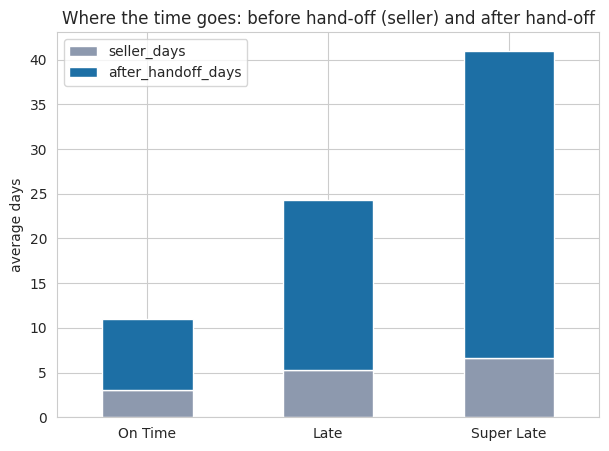

In [28]:
times = stage.groupby('delivery_status')[['seller_days', 'after_handoff_days']].mean().reindex(status_order)
times['promised_days'] = stage.groupby('delivery_status')['promised_days'].mean()
print(times)

times[['seller_days', 'after_handoff_days']].plot(kind='bar', stacked=True, figsize=(7, 5), color=['#8d99ae', '#1d6fa5'])
plt.xticks(rotation=0)
plt.xlabel('')
plt.ylabel('average days')
plt.title('Where the time goes: before hand-off (seller) and after hand-off')
plt.show()

late % when seller met the deadline: 5.4
late % when seller missed the deadline: 20.9

late orders where the seller missed the deadline: 27.8 %
late orders where the seller was on time: 72.2 %


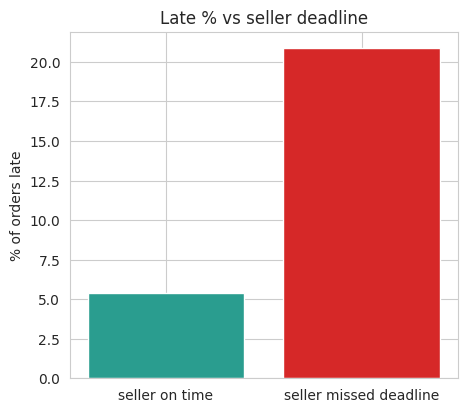

In [29]:
late_by_seller = stage.groupby('seller_missed')['is_late'].mean() * 100
print('late % when seller met the deadline:', round(late_by_seller[False], 1))
print('late % when seller missed the deadline:', round(late_by_seller[True], 1))
print()

late_stage = stage[stage['is_late']]
seller_share = late_stage['seller_missed'].mean() * 100
print('late orders where the seller missed the deadline:', round(seller_share, 1), '%')
print('late orders where the seller was on time:', round(100 - seller_share, 1), '%')

plt.figure(figsize=(5, 4.5))
plt.bar(['seller on time', 'seller missed deadline'], late_by_seller.values, color=['#2a9d8f', '#d62828'])
plt.ylabel('% of orders late')
plt.title('Late % vs seller deadline')
plt.show()

In [30]:
days_over = (stage['order_delivered_carrier_date'] - stage['shipping_limit']).dt.days.clip(lower=0)
new_difference = stage['Days_Difference'] + days_over

late_now = (stage['Days_Difference'] < 0).sum()
late_if_fixed = (new_difference < 0).sum()
print('late orders now:', late_now)
print('late orders if sellers were always on time:', late_if_fixed)
print('orders that would not be late:', late_now - late_if_fixed, '(' + str(round((late_now - late_if_fixed) / late_now * 100, 1)) + '% of late orders)')

late orders now: 6531
late orders if sellers were always on time: 5771
orders that would not be late: 760 (11.6% of late orders)


In [31]:
by_region = late_stage.groupby('region').agg(late_orders=('order_id', 'count'), seller_missed=('seller_missed', 'mean'),
                                             after_handoff_days=('after_handoff_days', 'mean'))
by_region['seller_missed'] = by_region['seller_missed'] * 100
print(by_region.sort_values('late_orders', ascending=False))
print()

worst_states = state.sort_values('late_pct', ascending=False).head(6).index
by_state_stage = late_stage[late_stage['customer_state'].isin(worst_states)].groupby('customer_state').agg(
    late_orders=('order_id', 'count'), seller_missed=('seller_missed', 'mean'), after_handoff_days=('after_handoff_days', 'mean'))
by_state_stage['seller_missed'] = by_state_stage['seller_missed'] * 100
print('worst 6 states (late orders only):')
print(by_state_stage)
print()
print('average days after hand-off, all orders:', round(stage['after_handoff_days'].mean(), 1))
print()

state_stage = stage.groupby('customer_state').agg(late_pct=('is_late', 'mean'), seller_days=('seller_days', 'mean'),
                                                  after_handoff_days=('after_handoff_days', 'mean'))
print('correlation of late % with average seller days:', round(state_stage['late_pct'].corr(state_stage['seller_days'], method='spearman'), 2))
print('correlation of late % with average days after hand-off:', round(state_stage['late_pct'].corr(state_stage['after_handoff_days'], method='spearman'), 2))
print('average seller days by state goes from', round(state_stage['seller_days'].min(), 2), 'to', round(state_stage['seller_days'].max(), 2))

              late_orders  seller_missed  after_handoff_days
region                                                      
Southeast            4046          31.74               24.66
Northeast            1149          17.75               36.06
South                 815          24.91               29.15
Central-West          367          25.61               28.58
North                 154          18.83               43.32

worst 6 states (late orders only):
                late_orders  seller_missed  after_handoff_days
customer_state                                                
AL                       85          14.12               36.79
CE                      176          15.91               39.64
MA                      125          22.40               31.44
PI                       66          18.18               34.74
RR                        5          20.00               73.71
SE                       51          21.57               39.48

average days after hand-off, all

**What I found**

- Sellers matter: when the seller misses the hand-off deadline, the order is about 4 times more likely to be late (20.9% vs 5.4%).
- But most late orders (about 7 out of 10) follow an on-time hand-off. Late orders also spend much longer after hand-off (19 days, and 34 days for super late) than on time orders (8 days). Part of that is by definition, because an order that is late took longer overall.
- Seller delays are a smaller but real lever: if every seller handed over on time, about 12% of late orders (760 orders) would disappear. The exact number moves between about 11% and 13% depending on how partial days are rounded.
- Across states, average seller time is more related to late % (correlation 0.54) than the time after hand-off (0.32), but seller time only goes from about 3 to 4 days between states, so I would not read too much into it.
- In the worst Northeast states, only 14-22% of late orders involve a late seller, so the delay mostly happens after hand-off or in a promise that is too short. The data doesn't say which carrier.

| Problem | What Veridi can do |
|---|---|
| Delay after hand-off in the Northeast (the data has no carrier field) | find out why: get carrier and tracking data for these states, then decide if carriers or hubs need to change |
| Estimate not adjusted per state | set the promised date from how long deliveries really take in that state, not a flat cushion |
| 3 bad months (picked because they were the worst, cause unknown) | investigate what happened in Nov 2017, Feb 2018 and Mar 2018 |
| Sellers missing deadlines | seller scorecards and penalties (smaller but real effect) |

## 8. Save tables for the dashboard

In [32]:
import os
os.makedirs('dashboard_data', exist_ok=True)

state.to_csv('dashboard_data/state_summary.csv')
monthly.to_csv('dashboard_data/monthly_trend.csv')
category.to_csv('dashboard_data/category_summary.csv')
avg_review.to_csv('dashboard_data/review_by_delivery_status.csv')

slim = stage[['order_id', 'customer_state', 'region', 'delivery_status', 'Days_Difference', 'promised_days',
              'actual_days', 'seller_days', 'after_handoff_days', 'seller_missed', 'review_score']].copy()
slim['purchase_month'] = stage['month']
slim.to_csv('dashboard_data/orders_slim.csv', index=False)
order_cat.to_csv('dashboard_data/order_category.csv', index=False)

for f in os.listdir('dashboard_data'):
    print(f, round(os.path.getsize('dashboard_data/' + f) / 1024), 'KB')

state_summary.csv 6 KB
monthly_trend.csv 1 KB
category_summary.csv 4 KB
orders_slim.csv 10910 KB
review_by_delivery_status.csv 0 KB
order_category.csv 5670 KB


## Answer to the CEO

**Is it specific regions or nationwide? Both.**

1. A nationwide problem in 3 months (Nov 2017, Feb 2018, Mar 2018): the late rate was about 15% in those months against 4.5% in the rest, in every region. I picked these months because they were the worst, and I don't know the cause, so it needs to be investigated.
2. A regional problem in the Northeast, which is late about twice as often as the rest of the country even in normal months.

About her idea on the estimates: she is only half right. On average the estimates are too long, not too short (92% of orders arrive before the date). But the cushion is not the same for every state, and the worst states get too little. When we miss the date, reviews drop a lot (4.3 stars on time vs 1.7 stars when more than 5 days late).